<a href="https://colab.research.google.com/github/UnnimayaVAshok/Data_Science/blob/main/Class_works/git_hub_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data = pd.read_csv('https://raw.githubusercontent.com/arib168/data/main/50_Startups.csv')
df = pd.DataFrame(data)
df

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94
5,131876.90,99814.71,362861.36,New York,156991.12
6,134615.46,147198.87,127716.82,California,156122.51
7,130298.13,145530.06,323876.68,Florida,155752.60
8,120542.52,148718.95,311613.29,New York,152211.77
9,123334.88,108679.17,304981.62,California,149759.96


In [ ]:
df.shape

(50, 5)

In [ ]:
df.columns

Index(['R&D Spend', 'Administration', 'Marketing Spend', 'State', 'Profit'], dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     object 
 4   Profit           50 non-null     float64
dtypes: float64(4), object(1)
memory usage: 2.1+ KB


In [ ]:
df.describe(include="all")

,R&D Spend,Administration,Marketing Spend,State,Profit
count,50.000000,50.000000,50.000000,50,50.000000
unique,NaN,NaN,NaN,3,NaN
top,NaN,NaN,NaN,New York,NaN
freq,NaN,NaN,NaN,17,NaN
mean,73721.615600,121344.639600,211025.097800,NaN,112012.639200
std,45902.256482,28017.802755,122290.310726,NaN,40306.180338
min,0.000000,51283.140000,0.000000,NaN,14681.400000
25%,39936.370000,103730.875000,129300.132500,NaN,90138.902500
50%,73051.080000,122699.795000,212716.240000,NaN,107978.190000
75%,101602.800000,144842.180000,299469.085000,NaN,139765.977500


In [ ]:
df.dtypes

,0
R&D Spend,float64
Administration,float64
Marketing Spend,float64
State,object
Profit,float64


In [ ]:
df.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [ ]:
df.tail()

,R&D Spend,Administration,Marketing Spend,State,Profit
45,1000.23,124153.04,1903.93,New York,64926.08
46,1315.46,115816.21,297114.46,Florida,49490.75
47,0.00,135426.92,0.00,California,42559.73
48,542.05,51743.15,0.00,New York,35673.41
49,0.00,116983.80,45173.06,California,14681.40


In [ ]:
df.isna().sum()

,0
R&D Spend,0
Administration,0
Marketing Spend,0
State,0
Profit,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df_1 = df["State"].value_counts()

Text(0.5, 1.0, 'Count of states')

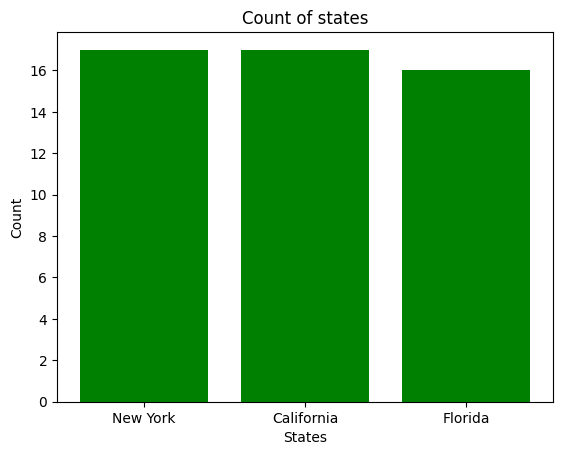

In [ ]:
plt.bar(df_1.index,df_1.values,color="g")
plt.xlabel("States")
plt.ylabel("Count")
plt.title("Count of states")

In [ ]:
x = df.iloc[:,:-1]
y = df.iloc[:,-1]

In [ ]:
# Feature selection
df.corr(numeric_only=True)

,R&D Spend,Administration,Marketing Spend,Profit
R&D Spend,1.000000,0.241955,0.724248,0.972900
Administration,0.241955,1.000000,-0.032154,0.200717
Marketing Spend,0.724248,-0.032154,1.000000,0.747766
Profit,0.972900,0.200717,0.747766,1.000000


Text(0.5, 1.0, 'Heatmap')

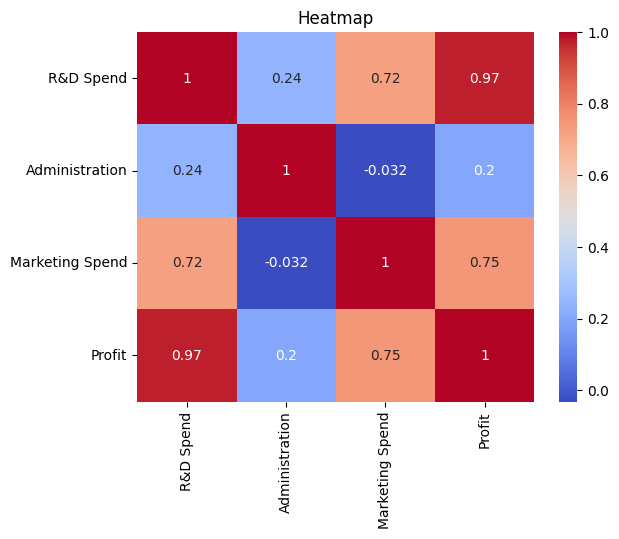

In [ ]:
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap="coolwarm")
plt.title("Heatmap")

<Axes: xlabel='R&D Spend', ylabel='Profit'>

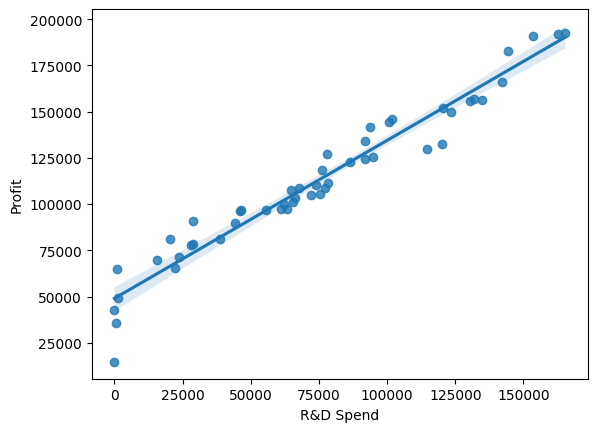

In [ ]:
sns.regplot(x=df['R&D Spend'],y=y)

<Axes: xlabel='Administration', ylabel='Profit'>

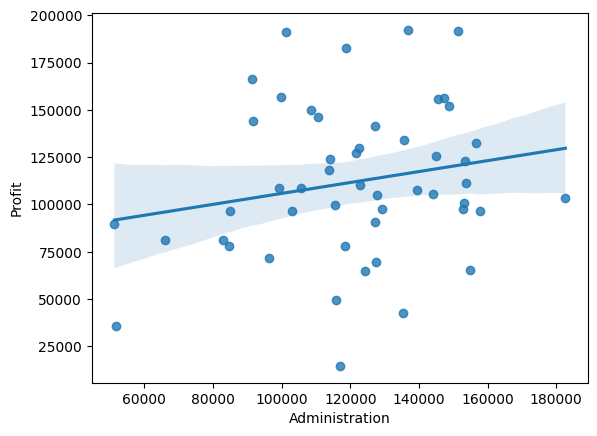

In [ ]:
sns.regplot(x=df['Administration'],y=y)

<Axes: xlabel='Marketing Spend', ylabel='Profit'>

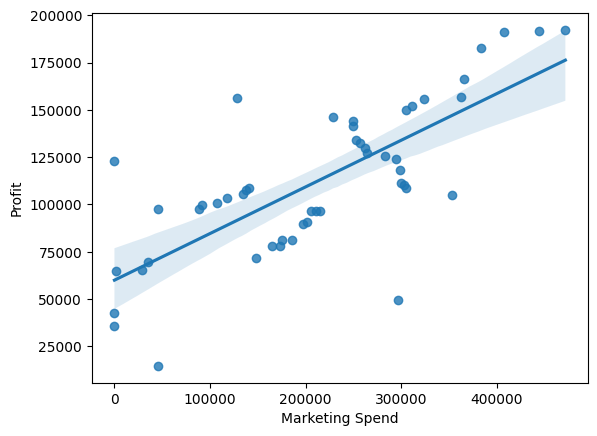

In [ ]:
sns.regplot(x=df['Marketing Spend'],y=y)

In [ ]:
# One hot encoding
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder

col_data = make_column_transformer((OneHotEncoder(handle_unknown="ignore"),["State"]),remainder="passthrough")
# handle unknown is used to ignore data which is not trained or not present in State column
# remainder is used to remain the other column itself

input = col_data.fit_transform(x)
input

array([[0.0000000e+00, 0.0000000e+00, 1.0000000e+00, 1.6534920e+05,
        1.3689780e+05, 4.7178410e+05],
       [1.0000000e+00, 0.0000000e+00, 0.0000000e+00, 1.6259770e+05,
        1.5137759e+05, 4.4389853e+05],
       [0.0000000e+00, 1.0000000e+00, 0.0000000e+00, 1.5344151e+05,
        1.0114555e+05, 4.0793454e+05],
       [0.0000000e+00, 0.0000000e+00, 1.0000000e+00, 1.4437241e+05,
        1.1867185e+05, 3.8319962e+05],
       [0.0000000e+00, 1.0000000e+00, 0.0000000e+00, 1.4210734e+05,
        9.1391770e+04, 3.6616842e+05],
       [0.0000000e+00, 0.0000000e+00, 1.0000000e+00, 1.3187690e+05,
        9.9814710e+04, 3.6286136e+05],
       [1.0000000e+00, 0.0000000e+00, 0.0000000e+00, 1.3461546e+05,
        1.4719887e+05, 1.2771682e+05],
       [0.0000000e+00, 1.0000000e+00, 0.0000000e+00, 1.3029813e+05,
        1.4553006e+05, 3.2387668e+05],
       [0.0000000e+00, 0.0000000e+00, 1.0000000e+00, 1.2054252e+05,
        1.4871895e+05, 3.1161329e+05],
       [1.0000000e+00, 0.0000000e+00,

In [ ]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(input,y,test_size=0.3,random_state=42)

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x_train,y_train)
y_pred = model.predict(x_test)
y_pred

array([126187.39411505,  85788.82259512,  99777.02815178,  45706.12238329,
       127062.20722772,  51891.83884459, 109114.62977495, 100600.61123702,
        97953.99874716, 111730.5770681 , 128818.49200668, 174195.35772631,
        93736.28538438, 148381.0409716 , 172313.87139388])

In [ ]:
df_2 = pd.DataFrame({"Actual_value":y_test,"Predicted_value":y_pred,"Difference":y_test - y_pred})
df_2

,Actual_value,Predicted_value,Difference
13,134307.35,126187.394115,8119.955885
39,81005.76,85788.822595,-4783.062595
30,99937.59,99777.028152,160.561848
45,64926.08,45706.122383,19219.957617
17,125370.37,127062.207228,-1691.837228
48,35673.41,51891.838845,-16218.428845
26,105733.54,109114.629775,-3381.089775
25,107404.34,100600.611237,6803.728763
32,97427.84,97953.998747,-526.158747
19,122776.86,111730.577068,11046.282932


In [ ]:
from sklearn.metrics import mean_absolute_percentage_error,r2_score

mape = mean_absolute_percentage_error(y_test,y_pred)
score = r2_score(y_test,y_pred)
print(mape,score)

0.08929865344172414 0.9397108063356046
